# Nuclear Power Reactors Output Power Data

We will use this script to get the power output data for each of the 94 operating nuclear power reactors from 2000 - 2025 from the [Nuclear Regulatory Commision](https://www.nrc.gov/documents-reports/document-collections/events-reports-associated-with/power-reactor-status-reports/)

In [292]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
from pathlib import Path

# This library helps us to visualize the progress of our data download
from tqdm.auto import tqdm

# Multi Threading
from concurrent.futures import ThreadPoolExecutor
import time

In [293]:
import threading

thread_local = threading.local()

# requests.get() sets up a new connection every time with the NRC website
# Howeveer there is a way to just start a session and keep working in that via requests.Session()
# Another way to make this process fatser is using ThreadPoolExecutor so there are mutliple threads working paralleley 
# But in that case we need a define a seperate session for each working thread 

def get_session():
    # The first time a thread calls this, it has no session yet, so make one.
    # Every later call from that same thread reuses it.
    if not hasattr(thread_local, "session"):
        thread_local.session = requests.Session()
    return thread_local.session

outdir = Path("/Users/vassu/Desktop/Erdos_DataScience/NuclearReliability/reactor_data")
outdir.mkdir(exist_ok=True)

URL="https://www.nrc.gov/documents-reports/document-collections/events-reports-associated-with/power-reactor-status-reports/"

def get_daily_data(date):

    Full_URL = URL + f'{date.year}/{date:%Y%m%d}ps'

    for attempt in range(3):
        
        webpage = get_session().get(Full_URL, timeout=60)
        if webpage.ok:
            break
        time.sleep(30)
    
    if not webpage.ok:
        print("Could not fetch data for", date.date())
        return None

    time.sleep(0.25)
    
    soup = BeautifulSoup(webpage.content, "html.parser")
    rows = []
    
    for table in soup.find_all("table"):

        # Each table sits right after a heading like <h3>Region 1</h3>
        heading = table.find_previous("h3")
        region = heading.get_text(strip=True) if heading else None

        for row in table.find_all("tr"):
    
            # Unit, Power, Down, Reason, Change in report, Scrams
            cells = [ td.get_text(strip=True) for td in row.find_all("td") ]
            if len(cells) != 6:
                continue
            rows.append({"date": date, "Region": region, "Unit": cells[0], "Power": cells[1], "Down": cells[2], "Reason": cells[3]})

    return rows

# An empty list to hold the names of the yearly csv files with daily reports
report_list = []

# The start is inclusive but stop is excluded
for year in range(2005, 2026):

    outfile = outdir / f'{year}DailyReports.csv'

    if not outfile.exists():

        dates = pd.date_range(f'{year}-01-01', f'{year}-12-31')
        year_rows = []

        # get_daily_data returns a list of dicts [dict1, dict2 , ...]
        # daily_rows would be a list of list -- > [ [dict1, dict2], [dict3, dict4] ]
        with ThreadPoolExecutor(max_workers=2) as pool:
            daily_rows = list( tqdm(pool.map(get_daily_data, dates), total=len(dates), desc=str(year)))

        failed = sum(rows is None for rows in daily_rows)
        if failed > 0:
            print(f'{year}: {failed} days failed, not saving. Rerun this cell later.')
            continue

        # This will basically give you [ dict1, dict2, dict3, dict4 ]
        for rows in daily_rows:
            year_rows.extend(rows)

        pd.DataFrame(year_rows).to_csv(outfile, index=False)

    report_list.append(pd.read_csv(outfile, parse_dates=["date"])) # Read the date column as a date not a text

df = pd.concat(report_list, ignore_index=True)  
print(df.head())

        date    Region              Unit  Power Down Reason
0 2005-01-01  Region 1   Beaver Valley 1    100  NaN    NaN
1 2005-01-01  Region 1   Beaver Valley 2    100  NaN    NaN
2 2005-01-01  Region 1  Calvert Cliffs 1    100  NaN    NaN
3 2005-01-01  Region 1  Calvert Cliffs 2    100  NaN    NaN
4 2005-01-01  Region 1       FitzPatrick    100  NaN    NaN


In [294]:
print("From the daily reports spanning 2005-2025 we have", df["Unit"].nunique(), "recators.")
print("Number of rows in the dataframe", len(df))

From the daily reports spanning 2005-2025 we have 110 recators.
Number of rows in the dataframe 764898


### Cleaning the power data

The daily power files for 2005–2025 contain **110 different reactors**, but
`get_reactor_list.ipynb` found only **94 currently operating** reactors. The
difference comes from reactors that have shut down since 2005.

Before analysis, the data needs some cleaning:

1. **Keep only operating reactors.** Drop the reactors that are not in the reactor list from `get_reactor_list.ipynb`.
2. **Match reactor names.** The two NRC sources spell some names differently (e.g. `Arkansas Nuclear 1` in the power data vs `Arkansas Nuclear One 1` in the reactor list), so these names must be made consistent before joining.

                          min        max  count
Unit                                           
Arkansas Nuclear 1 2005-01-01 2025-12-31   7666
Arkansas Nuclear 2 2005-01-01 2025-12-31   7666
Beaver Valley 1    2005-01-01 2025-12-31   7666
Beaver Valley 2    2005-01-01 2025-12-31   7666
Braidwood 1        2005-01-01 2025-12-31   7666


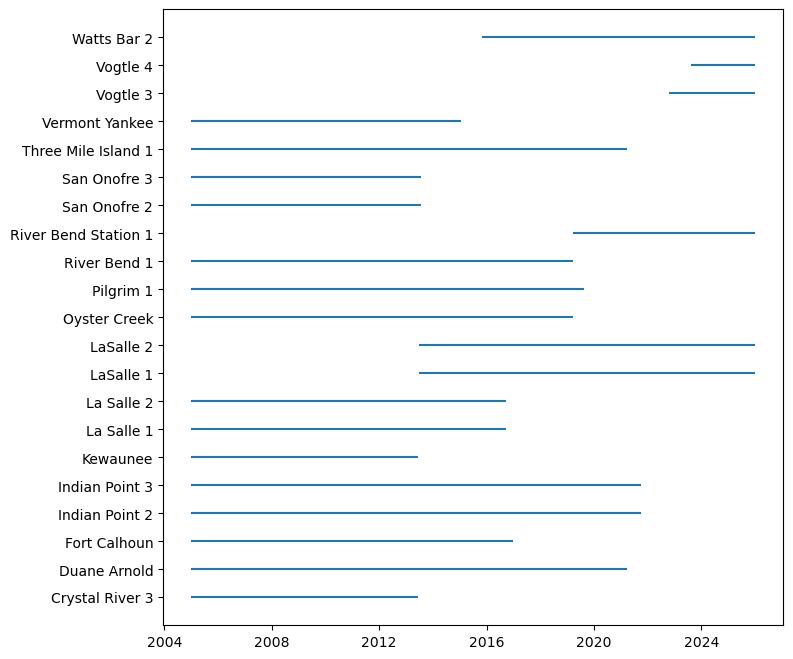

In [295]:
runtime_df = df.groupby("Unit")["date"].agg(["min", "max", "count"])
print(runtime_df.head())

runtime_filtered_df = runtime_df[ (runtime_df["min"] > "2005-01-01") | (runtime_df["max"] < "2025-12-31")]

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(8,8))
plt.hlines(y=runtime_filtered_df.index, xmin=runtime_filtered_df["min"], xmax=runtime_filtered_df["max"])
plt.show()


As can be seen in the above plot, 12 nuclear power reactors are not currently operating. We would drop the data from these reactors.

**We need to rename some units to have naming consistency**
1. La Salle 1 --> LaSelle 1
2. La Selle 2 --> LaSelle 2
3. River Bend 1 --> River Bend Station 1

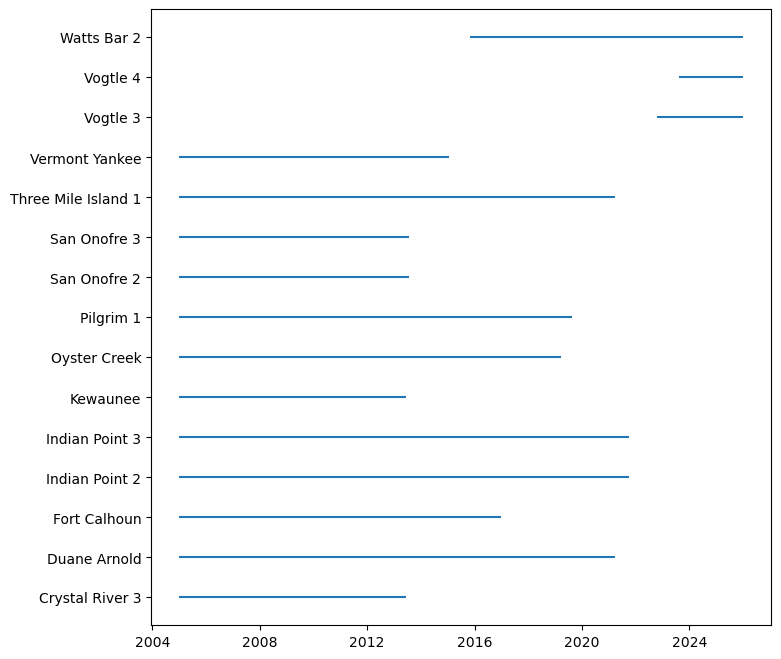

In [296]:
df["Unit"] = df["Unit"].replace({ "LaSalle 1": "La Salle 1", "LaSalle 2": "La Salle 2", "River Bend Station 1": "River Bend 1" })
runtime_df = df.groupby("Unit")["date"].agg(["min", "max", "count"])
runtime_filtered_df = runtime_df[ (runtime_df["min"] > "2005-01-01" ) | (runtime_df["max"] < "2025-12-31") ]

plt.figure(figsize=(8,8))
plt.hlines(y=runtime_filtered_df.index, xmin=runtime_filtered_df["min"], xmax=runtime_filtered_df["max"])
plt.show()

In [297]:
unoperating_reactors = runtime_filtered_df[ runtime_filtered_df["max"] < "2025-12-31" ].index

In [298]:
new_df = df.drop(df[ df["Unit"].isin(unoperating_reactors) ].index).reset_index(drop=True)
print(new_df.head())
print("Number of rows and columns", new_df.shape)

print("After removing currently unoperating reactors, we now have", new_df["Unit"].nunique(), "reactors")

        date    Region              Unit  Power Down Reason
0 2005-01-01  Region 1   Beaver Valley 1    100  NaN    NaN
1 2005-01-01  Region 1   Beaver Valley 2    100  NaN    NaN
2 2005-01-01  Region 1  Calvert Cliffs 1    100  NaN    NaN
3 2005-01-01  Region 1  Calvert Cliffs 2    100  NaN    NaN
4 2005-01-01  Region 1       FitzPatrick    100  NaN    NaN
Number of rows and columns (709855, 6)
After removing currently unoperating reactors, we now have 95 reactors


As can be seen we still have one extra reactor relative to the currently operating reactors list. Let's find out which one is that

In [299]:

currently_operating_reactors = outdir / "reactor_list.csv"
currently_operating_reactors_df = pd.read_csv(currently_operating_reactors)
print(currently_operating_reactors_df.columns)

a = set(currently_operating_reactors_df["name"])
b = set(new_df["Unit"])

print("The reactors in the currently operating list that are not in the analyzed dataframe from daily reports", a-b)
print("The reactors in the analyzed dataframe from daily reports but not in the currently operating list", b-a)


Index(['code', 'name', 'Region', 'State'], dtype='str')
The reactors in the currently operating list that are not in the analyzed dataframe from daily reports {'Arkansas Nuclear One 2', 'Arkansas Nuclear One 1', 'V.C. Summer'}
The reactors in the analyzed dataframe from daily reports but not in the currently operating list {'Arkansas Nuclear 2', 'Palisades', 'Arkansas Nuclear 1', 'Summer'}


We can see that there are 3 naming mismatches and one reactor `Palisades` just not there in the currently operating list

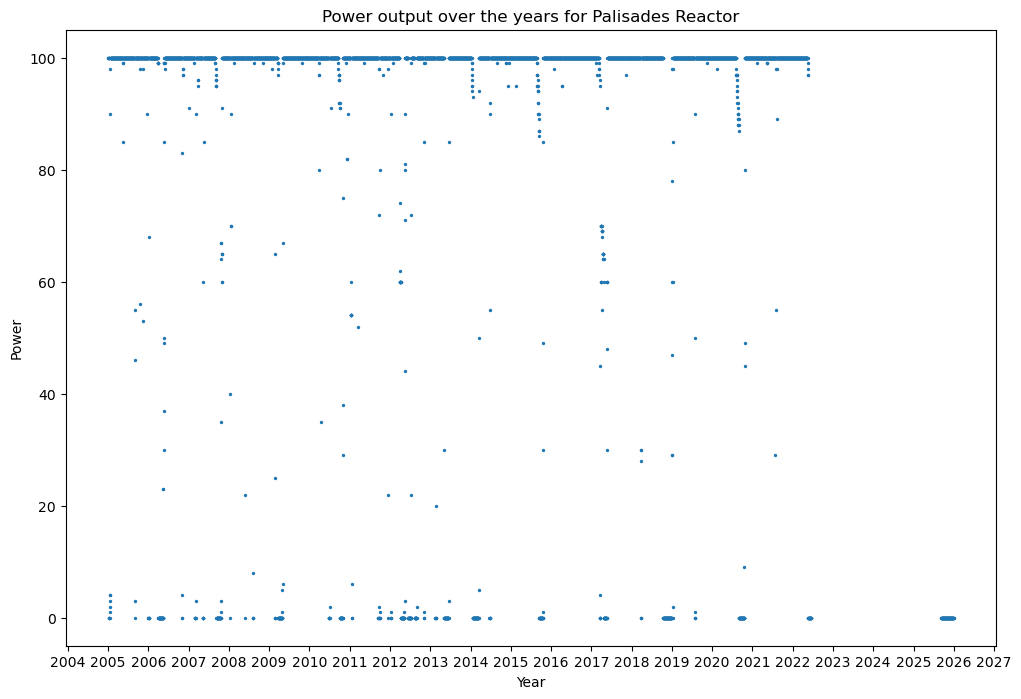

In [300]:
new_df["Unit"] = new_df["Unit"].replace({"Arkansas Nuclear 1": "Arkansas Nuclear One 1", "Arkansas Nuclear 2": "Arkansas Nuclear One 2", "Summer": "V.C. Summer"})

plt.figure(figsize=(12,8))
plt.scatter(new_df[new_df["Unit"] == "Palisades"].date, new_df[new_df["Unit"] == "Palisades"].Power, s=2)
plt.xlabel("Year")
plt.ylabel("Power")
plt.title("Power output over the years for Palisades Reactor")

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())

As can be seen in the plot above, the reactor did not report any power output data after mid 2022 but there are some data at the end of 2025 which is why it passed our filters above. Nevertheless we can remove it from our analysis as it is indeed not currently operating

In [301]:
new_df = new_df.drop( new_df[new_df["Unit"] == "Palisades"].index ).reset_index(drop=True)
a = set(currently_operating_reactors_df["name"])
b = set(new_df["Unit"])

print("The reactors in the currently operating list that are not in the analyzed dataframe from daily reports", a-b)
print("The reactors in the analyzed dataframe from daily reports but not in the currently operating list", b-a)

print("The number of rows in the dataframe", len(new_df))

The reactors in the currently operating list that are not in the analyzed dataframe from daily reports set()
The reactors in the analyzed dataframe from daily reports but not in the currently operating list set()
The number of rows in the dataframe 703368


Another data cleaning step requires identifying any duplicates in the data. For that we can use the inbuilt `duplicate` fucntion in pandas

In [302]:
new_df.duplicated(keep="first").sum()
print("There are 67 duplicates in the data frame")

There are 67 duplicates in the data frame


In [303]:
new_df = new_df.drop_duplicates(subset=["Unit", "date"], keep="first").reset_index(drop=True)
print(new_df.shape)

(703272, 6)


Next thing we want to make sure is that there are no missing days for any reactor. You can see that grouping the df by Unit is the sensible choice here. We will sort the dataframe first by the "Unit" and then by the "date" and finally use the .diff() command (this date minus the previous date), if there are no gaps the only value available would be 1

In [304]:
new_df = new_df.sort_values(["Unit", "date"]).reset_index(drop=True)
new_df["gap"] = new_df.groupby("Unit")["date"].diff().dt.days

gap_rows = new_df[new_df["gap"] > 1]
gap_rows[["date", "gap"]].value_counts()

date        gap
2015-12-05  4.0    92
2013-07-19  2.0    91
2013-12-22  2.0    91
Name: count, dtype: int64

As can be seen more than 90 reactors do not have any data starting these 3 dates. However looking at the yearly power reports it seems like the report is indeed available for these missing reorts but with one caveat that the reason if the power was down from 100% is not listed in those reports.

From the above cells we can see the gap dates are `(2013-07-18), (2013-12-21), (2015-12-04, 2015-12-03, 2015-12-02)`

In [305]:
missing_days = pd.to_datetime(["2013-07-18", "2013-12-21", "2015-12-02", "2015-12-03", "2015-12-04"])
yearly_data = pd.concat([ pd.read_csv(outdir/f'{year}PowerStatus.txt', sep="|", parse_dates=["ReportDt"]) for year in range(2013, 2016) ])

missing_data = yearly_data[ yearly_data["ReportDt"].isin(missing_days) ].sort_values("ReportDt").reset_index(drop=True)
missing_data.head()

,ReportDt,Unit,Power
0,2013-07-18,McGuire 2,100
1,2013-07-18,Dresden 2,100
2,2013-07-18,Dresden 3,100
3,2013-07-18,Duane Arnold,100
4,2013-07-18,Farley 1,100


Before merging these missing days with the main dataframe we need to account for the same naming inconsistencies as we dealt with before and remove the currently not oprating reactors

In [306]:
missing_data["Unit"] = missing_data["Unit"].replace({"LaSalle 1": "La Salle 1", "LaSalle 2": "La Salle 2", "River Bend Station 1": "River Bend 1", "Arkansas Nuclear 1": "Arkansas Nuclear One 1", "Arkansas Nuclear 2": "Arkansas Nuclear One 2", "Summer": "V.C. Summer"})

In [307]:
missing_data = missing_data[missing_data["Unit"].isin(currently_operating_reactors_df["name"])].reset_index(drop=True)

Now before we can merge it with our main dataframe we need to first make it the same structure as our `new_df` for that we need to rename "ReportDt" -- > "date", Add the `Region` column and then define the `Down` and the `Reason` columns. 

In [308]:
import numpy as np

missing_data = missing_data.rename(columns={"ReportDt":"date"})
missing_data["Down"] = np.nan # Matching new_df convention
missing_data["Reason"] = ["Not Available" if p < 100 else np.nan for p in missing_data["Power"]]

# For the region information we need a lookup table between Unit --> Region

unit_region_map = new_df.groupby("Unit")["Region"].first()

missing_data["Region"] = missing_data["Unit"].map(unit_region_map)

missing_data.duplicated(keep="first").sum()

np.int64(0)

In [309]:
new_df = pd.concat([new_df, missing_data], ignore_index=True)
new_df = new_df.sort_values(["Unit", "date"]).reset_index(drop=True)

new_df.groupby("Unit")["date"].diff().dt.days.value_counts()

date
1.0    703636
Name: count, dtype: int64

**We have accounted for all the missing data**

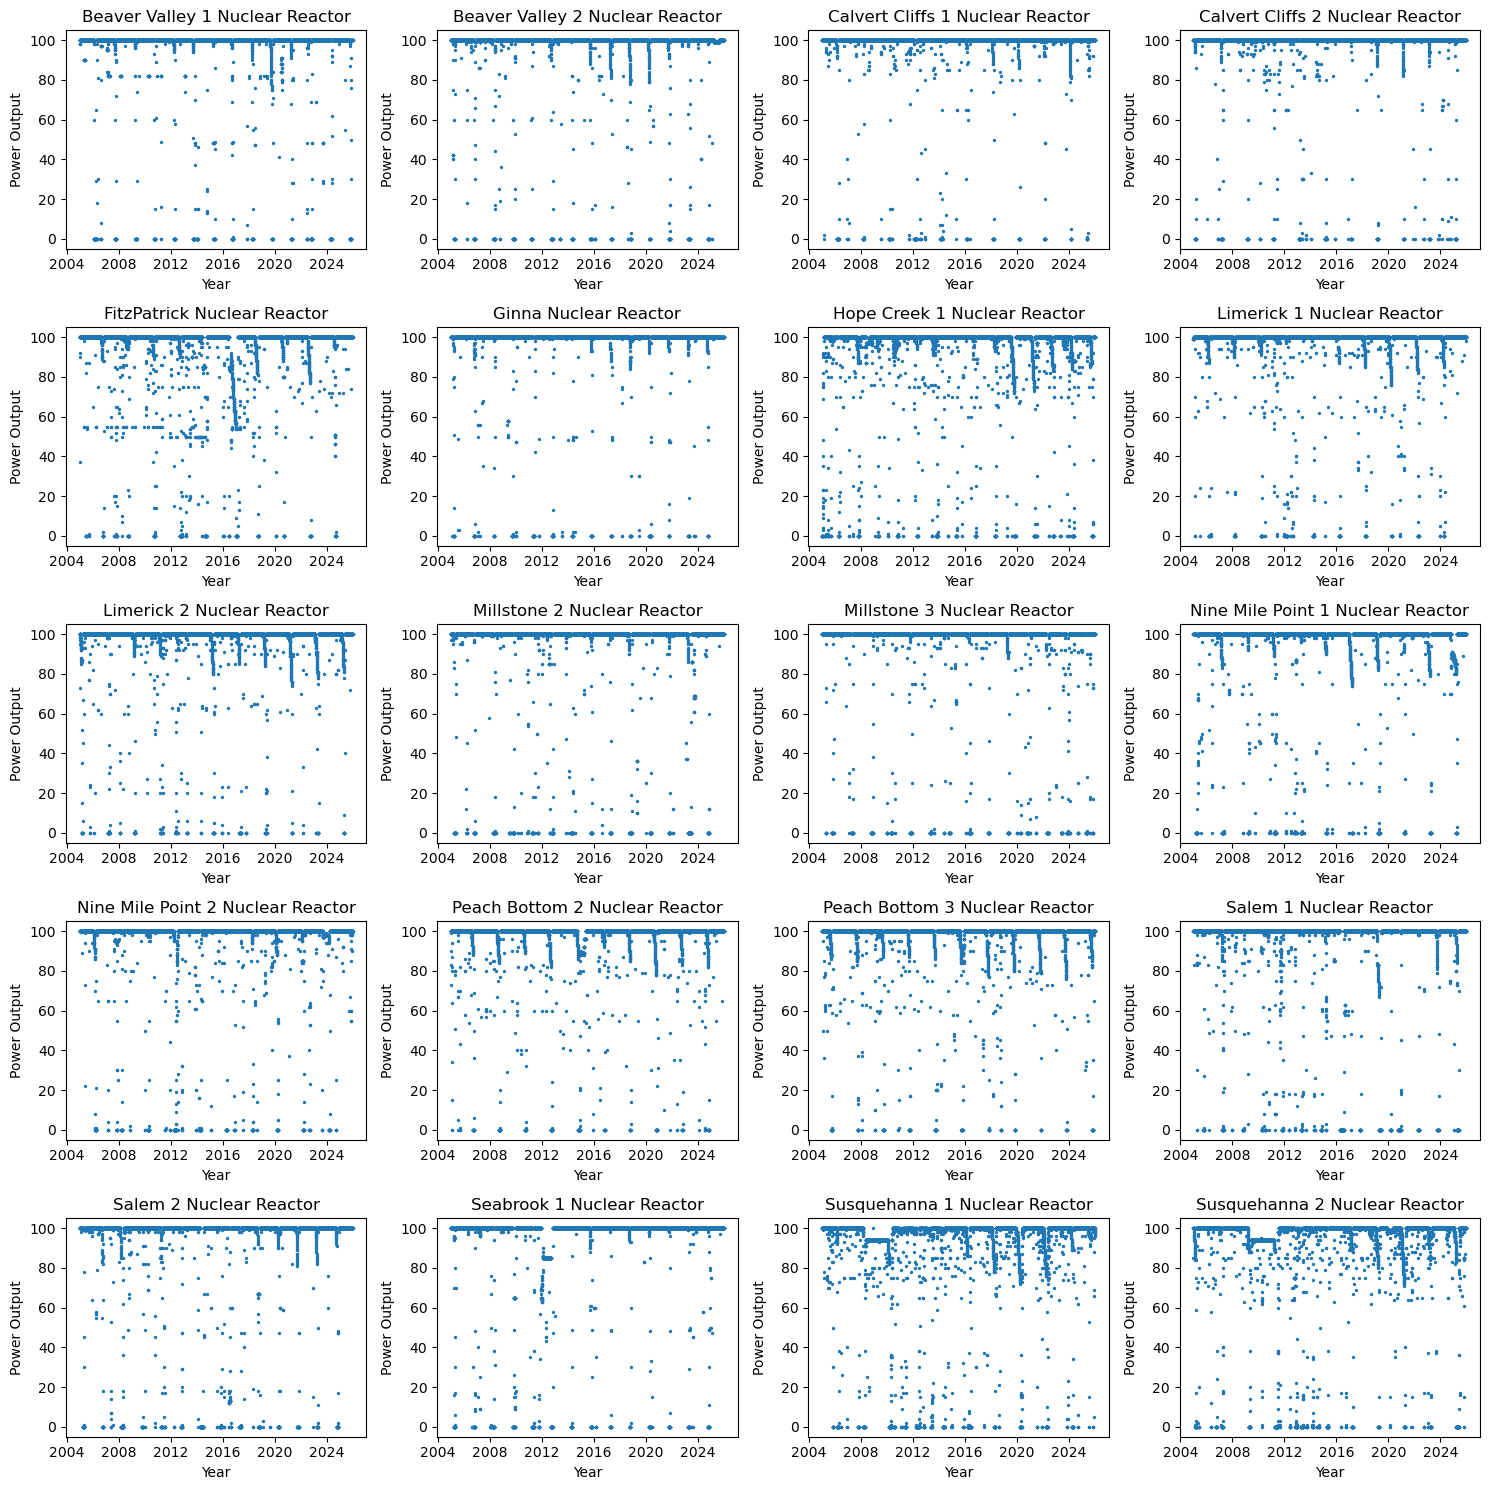

In [310]:
fig, axes = plt.subplots(5,4,figsize=(15,15))
axes = axes.flatten()

region1_reactors = new_df[new_df["Region"] == "Region 1"]
region1_reactor_names = sorted(region1_reactors["Unit"].unique())

for i in range(len(region1_reactor_names)):
    axes[i].scatter(region1_reactors[ region1_reactors["Unit"] == region1_reactor_names[i] ].date, region1_reactors[ region1_reactors["Unit"] == region1_reactor_names[i] ].Power, s=2)
    axes[i].set_xlabel("Year")
    axes[i].set_ylabel("Power Output")
    axes[i].set_title(f'{region1_reactor_names[i]} Nuclear Reactor')

plt.tight_layout()
plt.show()

In [311]:
rows = []

# unit holds the "Unit" name and unit_df holds the dataframe for each unit (The entire dataframe including Unit itself)

for unit, unit_df in new_df.groupby("Unit"):

    region = unit_df["Region"].iloc[0]

    count = 0

    for power, date, reason in zip(unit_df["Power"], unit_df["date"], unit_df["Reason"]):

        if power == 0:
            if count == 0:
                start = date
                outage_reason = np.nan # Initlialize to missing
            if pd.isna(outage_reason) and pd.notna(reason):
                outage_reason = reason
            count += 1
            end = date
        elif count > 0:
            rows.append({ "Unit":unit, "Region": region, "Start_Date": start, "End_Date": end, "Outage_Duration": count, "Reason":outage_reason })
            count = 0

    if count > 0:
        rows.append({ "Unit":unit, "Region": region, "Start_Date": start, "End_Date": end, "Outage_Duration": count , "Reason": outage_reason})

outages = pd.DataFrame(rows)
outages

,Unit,Region,Start_Date,End_Date,Outage_Duration,Reason
0,Arkansas Nuclear One 1,Region 4,2005-10-05,2005-12-21,78,SHUTDOWN FOR REFUELING OUTAGE
1,Arkansas Nuclear One 1,Region 4,2005-12-27,2005-12-29,3,TURBINE/REACTOR TRIP SEE EN#42229
2,Arkansas Nuclear One 1,Region 4,2007-04-23,2007-05-13,21,REFUELING OUTAGE
3,Arkansas Nuclear One 1,Region 4,2008-10-27,2008-12-11,46,REFUELING OUTAGE
4,Arkansas Nuclear One 1,Region 4,2008-12-21,2008-12-23,3,TRIP - SEE EN #44736.
...,...,...,...,...,...,...
2869,Wolf Creek 1,Region 4,2022-07-19,2022-07-21,3,See Event #56005
2870,Wolf Creek 1,Region 4,2022-10-06,2022-11-20,46,Refueling Outage
2871,Wolf Creek 1,Region 4,2024-03-28,2024-05-10,44,Refueling Outage
2872,Wolf Creek 1,Region 4,2024-08-24,2024-08-26,3,EN 57284


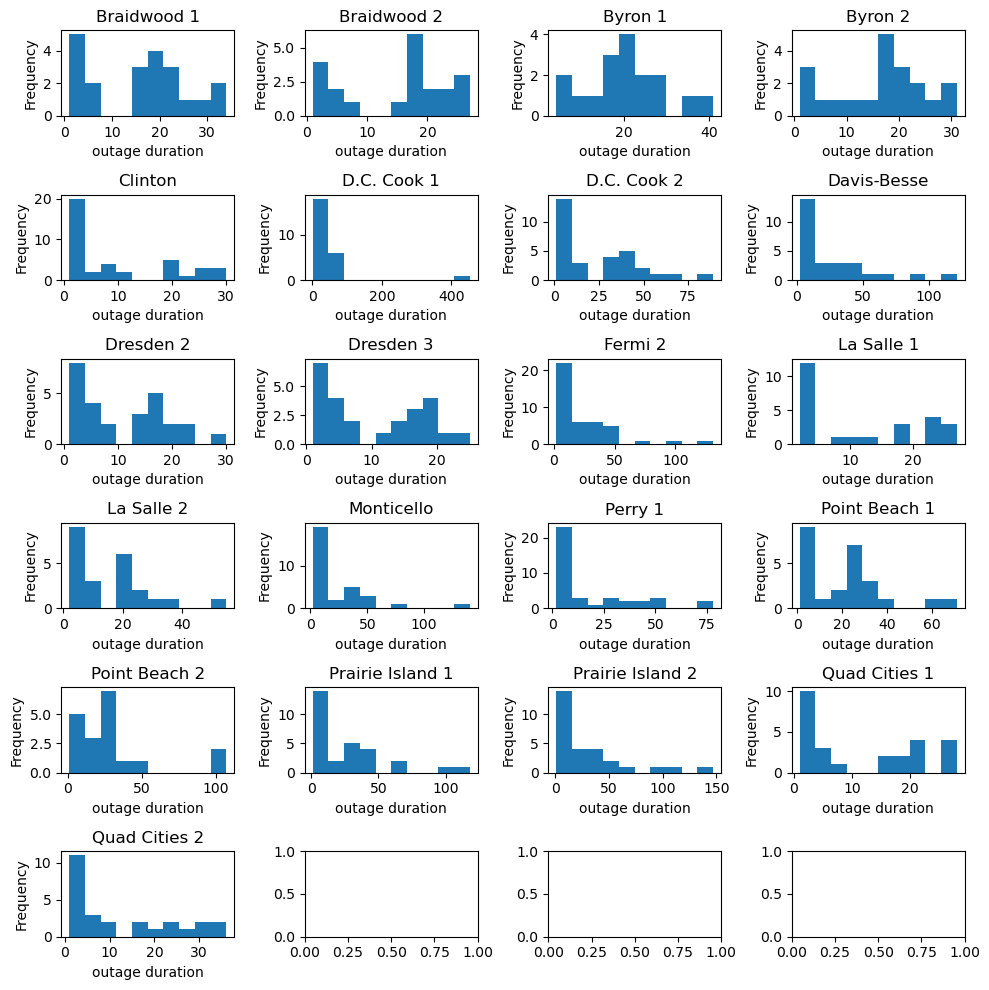

In [318]:
import math

region = "Region 3"

region_outages = outages[outages["Region"] == region]
region_reactors = region_outages["Unit"].unique()

n_plots = len(region_reactors)
n_cols = 4
n_rows = math.ceil(n_plots / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(10,10))
axes = axes.flatten()

for i in range(len(region_reactors)):

    axes[i].hist(region_outages[ region_outages["Unit"] == region_reactors[i] ].Outage_Duration, bins=10)
    axes[i].set_xlabel("outage duration")
    axes[i].set_ylabel("Frequency")
    axes[i].set_title(f'{region_reactors[i]}')

plt.tight_layout()
plt.show()